# Setup

In [8]:
from pathlib import Path
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import random

309 images trouvées


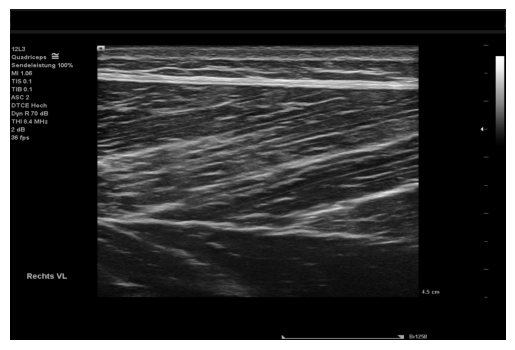

In [3]:
# Chercher les images de test
dossier = Path("data/test_images_v2")
images = [p for p in dossier.rglob("*")
          if p.suffix.lower() in (".png", ".tif", ".tiff")]

print(f"{len(images)} images trouvées")

# Afficher la première image
img = cv.imread(str(images[0]), cv.IMREAD_GRAYSCALE)

plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

# Removing borders

To remove the borders, we "scan" through our image using vertical & horizontal lines

1. Convert to grayscale: Convert the image to grayscale if it isn't already.

2. Select central bands: Extract a horizontal and a vertical band, each covering 20% of the image in its respective direction.

3. Calculate standard deviation profiles: Compute the standard deviation of pixel intensities for each column (horizontal profile) and each row (vertical profile).

4. Smooth the profiles: Apply a moving averaging filter

5. Apply a threshold: Identify regions where the standard deviation exceeds a given threshold, indicating textured areas.

6. Detect region boundaries: Find the start and end of each continuous region above the threshold.

7. Select the main region: Keep the longest continuous region in each profile

8. Add margins and crop: Expand the detected boundaries slightly and crop the original image using the resulting coordinates.

In [7]:
def main_region(profile, threshold=5):
    # Smooth the profile to reduce small variations
    profile = np.convolve(profile, np.ones(31)/31, mode="same")

    # Detect regions with sufficient intensity variation
    active = profile > threshold

    # Find the start and end of each detected region
    transitions = np.diff(np.r_[False, active, False].astype(int))
    starts = np.where(transitions == 1)[0]
    ends = np.where(transitions == -1)[0]

    if len(starts) == 0:
        return 0, len(profile)

    # Keep the longest continuous region
    i = np.argmax(ends - starts)

    return starts[i], ends[i]

In [6]:
def crop_image(img, threshold=5, margin=3):
    # Convert to grayscale if necessary
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY) if img.ndim == 3 else img

    h, w = gray.shape

    # Standard deviation of each column in the central horizontal band
    profile_x = np.std(gray[int(0.4*h):int(0.6*h), :], axis=0)

    # Standard deviation of each row in the central vertical band
    profile_y = np.std(gray[:, int(0.4*w):int(0.6*w)], axis=1)

    # Find the boundaries of the main region
    x0, x1 = main_region(profile_x, threshold)
    y0, y1 = main_region(profile_y, threshold)

    # Add a small margin to avoid errors
    x0, x1 = max(0, x0-margin), min(w, x1+margin)
    y0, y1 = max(0, y0-margin), min(h, y1+margin)

    return img[y0:y1, x0:x1]

We can than try our method onto random images from the dataset

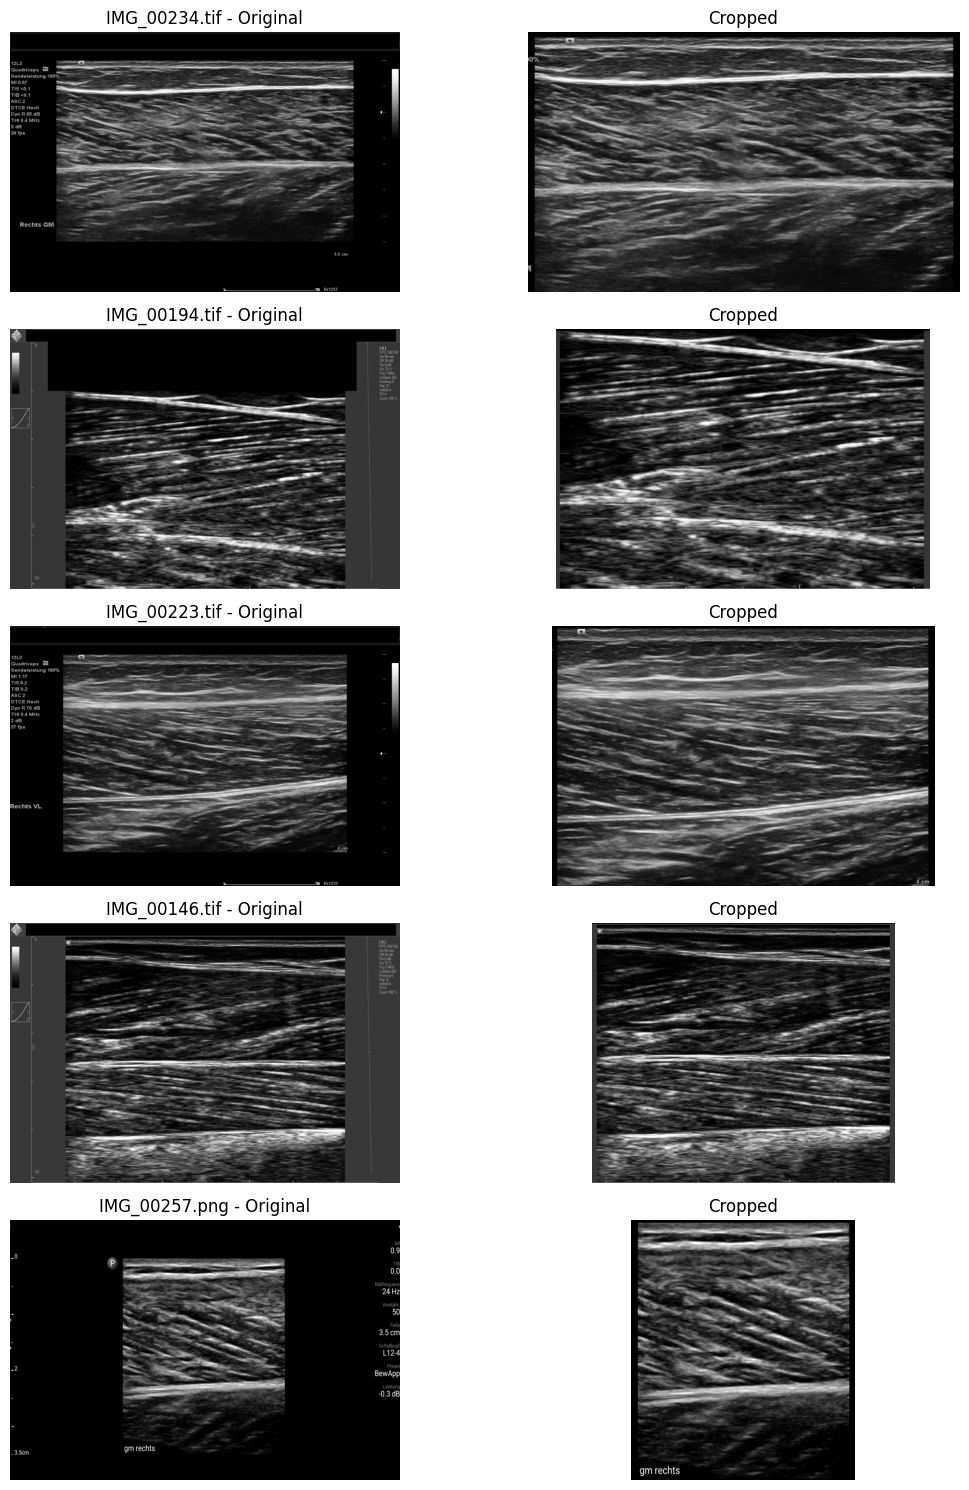

In [11]:
# Get all images from the dataset
folder = Path("data/test_images_v2")
images = sorted(
    p for p in folder.rglob("*")
    if p.suffix.lower() in (".tif", ".tiff", ".png", ".jpg")
)

random.seed(666)
selected = random.sample(images, 5)

# Display original and cropped images 
fig, axs = plt.subplots(5, 2, figsize=(12, 15))

for i, path in enumerate(selected):
    img = cv.imread(str(path), cv.IMREAD_GRAYSCALE)
    cropped = crop_image(img)

    axs[i, 0].imshow(img, cmap="gray")
    axs[i, 0].set_title(f"{path.name} - Original")

    axs[i, 1].imshow(cropped, cmap="gray")
    axs[i, 1].set_title("Cropped")

    for ax in axs[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

We can see that it's close to prefectly cropped, removing most of the overlay and making image analys actually doable